In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the project folder
PROJECT_DIR = Path.cwd().parent

# SHAP report files
REPORT_DIR = PROJECT_DIR / "reports"

importance_path = REPORT_DIR / "shap_feature_importance.csv"
predictions_path = REPORT_DIR / "shap_test_predictions.csv"
shap_values_path = REPORT_DIR / "shap_test_values.csv"

print("Project folder:", PROJECT_DIR)
print("Reports folder exists:", REPORT_DIR.exists())
print("Feature importance file exists:", importance_path.exists())
print("Test predictions file exists:", predictions_path.exists())
print("SHAP values file exists:", shap_values_path.exists())

Project folder: C:\Users\HP\HIV-Treatment-Failure-Prediction
Reports folder exists: True
Feature importance file exists: True
Test predictions file exists: True
SHAP values file exists: True


In [2]:
importance_df = pd.read_csv(importance_path)
predictions_df = pd.read_csv(predictions_path)
shap_df = pd.read_csv(shap_values_path)

print("Feature importance shape:", importance_df.shape)
print("Predictions shape:", predictions_df.shape)
print("SHAP values shape:", shap_df.shape)

print("\nFeature importance columns:")
print(importance_df.columns.tolist())

print("\nPrediction columns:")
print(predictions_df.columns.tolist())

print("\nSHAP values columns:")
print(shap_df.columns.tolist())

Feature importance shape: (57, 2)
Predictions shape: (505, 5)
SHAP values shape: (505, 58)

Feature importance columns:
['Feature', 'Mean_Absolute_SHAP']

Prediction columns:
['row_index', 'participant_id', 'actual_treatment_outcome', 'predicted_probability', 'predicted_class']

SHAP values columns:
['row_index', 'numeric__CD4', 'numeric__viral_load', 'numeric__year', 'numeric__CD4_previous', 'numeric__viral_load_previous', 'numeric__CD4_change', 'numeric__viral_load_change', 'numeric__years_since_previous_visit', 'categorical__sex_Male', 'categorical__VISIT_130', 'categorical__VISIT_140', 'categorical__VISIT_150', 'categorical__VISIT_160', 'categorical__VISIT_170', 'categorical__VISIT_180', 'categorical__VISIT_190', 'categorical__VISIT_200', 'categorical__VISIT_210', 'categorical__VISIT_220', 'categorical__VISIT_230', 'categorical__VISIT_240', 'categorical__VISIT_250', 'categorical__VISIT_260', 'categorical__VISIT_270', 'categorical__VISIT_280', 'categorical__VISIT_290', 'categorical_

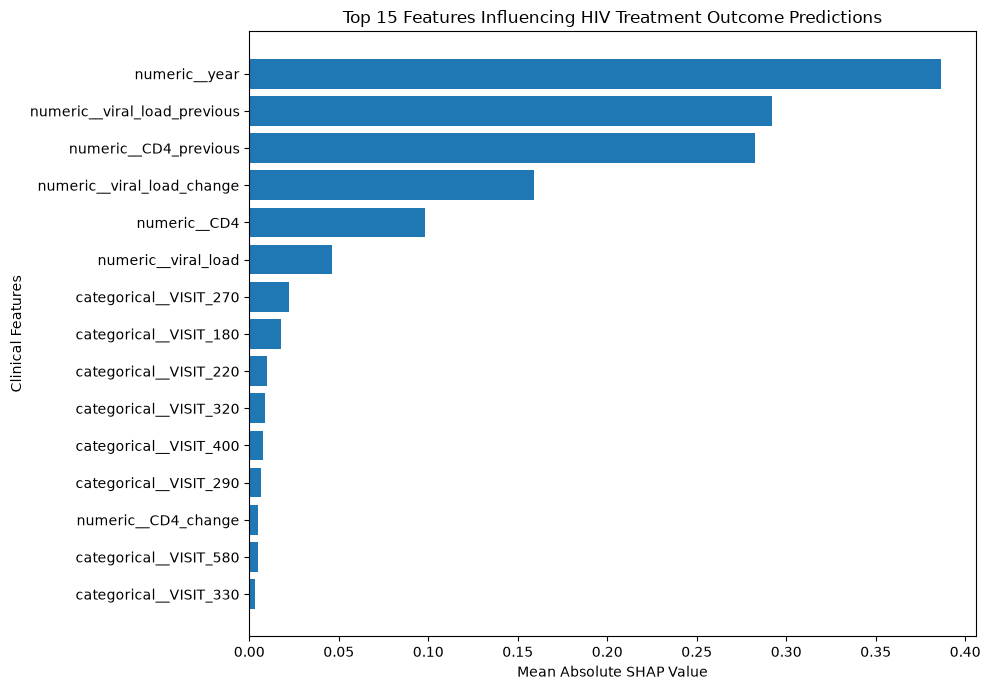

In [3]:
# Select the 15 most important features
top_features = importance_df.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).head(15)

# Plot the results
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Mean_Absolute_SHAP"][::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Clinical Features")
plt.title("Top 15 Features Influencing HIV Treatment Outcome Predictions")
plt.tight_layout()
plt.show()

### Interpretation of Global SHAP Feature Importance

The global SHAP analysis identifies the features that contribute most
to the model's predictions across the test dataset.

The five most influential features are:
1. Year
2. Previous viral load
3. Previous CD4 count
4. Viral load change
5. Current CD4 count

Year has the highest mean absolute SHAP value, followed by previous
viral load and previous CD4 count.

These results describe model behaviour, not causal relationships.
The importance of year should be investigated further to understand
possible temporal patterns or dataset-related effects.

The target represents a treatment-stop proxy and should not be
interpreted as independently confirmed clinical treatment failure.

### Interpretation of Global SHAP Feature Importance

The global SHAP analysis identifies the features that contribute most
to the model's predictions across the test dataset.

The five most influential features are:
1. Year
2. Previous viral load
3. Previous CD4 count
4. Viral load change
5. Current CD4 count

Year has the highest mean absolute SHAP value, followed by previous
viral load and previous CD4 count.

These results describe model behaviour, not causal relationships.
The importance of year should be investigated further to understand
possible temporal patterns or dataset-related effects.

The target represents a treatment-stop proxy and should not be
interpreted as independently confirmed clinical treatment failure.

Actual class: 0
Predicted class: 0
Predicted probability: 0.11565065551399352


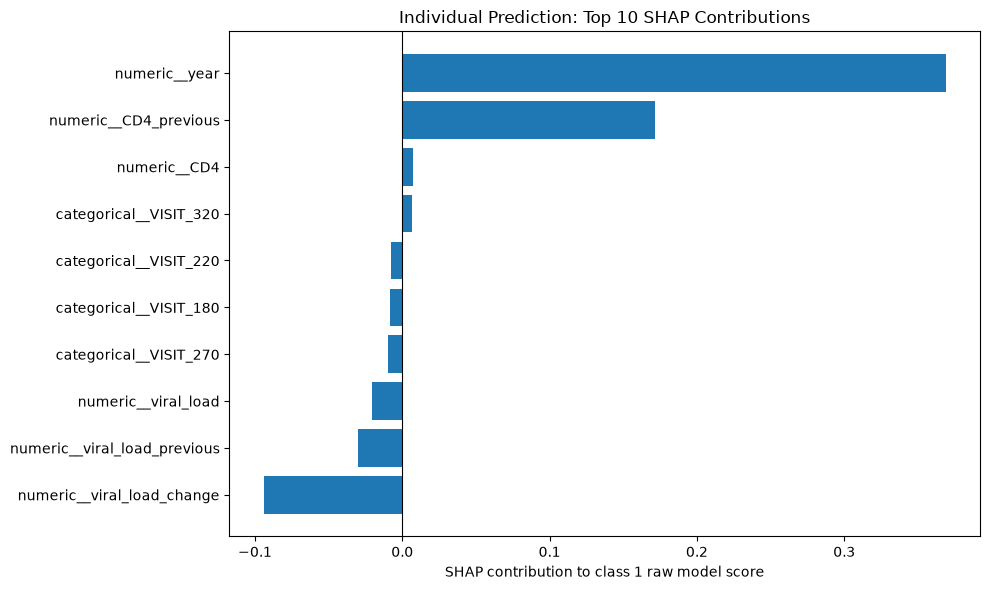

In [5]:
# Select one test prediction
patient = predictions_df.iloc[0]

# Find the matching SHAP explanation
patient_shap = shap_df[
    shap_df["row_index"] == patient["row_index"]
].iloc[0]

# Extract feature contributions
contributions = patient_shap.drop("row_index").sort_values()

# Select the 10 strongest contributions
top_contributions = contributions.loc[
    contributions.abs().nlargest(10).index
].sort_values()

# Display prediction details without patient identifiers
print("Actual class:", patient["actual_treatment_outcome"])
print("Predicted class:", patient["predicted_class"])
print("Predicted probability:", patient["predicted_probability"])

# Plot SHAP contributions
plt.figure(figsize=(10, 6))
plt.barh(top_contributions.index, top_contributions.values)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("SHAP contribution to class 1 raw model score")
plt.title("Individual Prediction: Top 10 SHAP Contributions")
plt.tight_layout()
plt.show()

### Interpretation of Individual SHAP Explanation

The selected test observation was classified as class 0.

The predicted probability of class 1 was approximately 11.57%.

The year feature had the strongest positive contribution towards the class 1 raw model score. Viral load change had the strongest negative contribution.

Previous CD4 count also contributed positively, while previous viral load contributed negatively.

These SHAP values explain how the model arrived at its prediction. They do not establish medical causation or independently confirm a patient's clinical outcome.

### SHAP Results Validation

This section checks whether the saved SHAP results are complete and consistent with the test predictions.

The checks include:
- Matching the number of SHAP rows and predictions.
- Checking for missing SHAP values.
- Checking that predicted probabilities are between 0 and 1.
- Confirming that the SHAP feature columns match the global importance report.

In [6]:
# Validation checks

shap_features = [
    col for col in shap_df.columns if col != "row_index"
]

importance_features = importance_df["Feature"].tolist()

print("SHAP rows match prediction rows:",
      len(shap_df) == len(predictions_df))

print("No missing SHAP values:",
      shap_df[shap_features].notna().all().all())

print("All SHAP values are finite:",
      __import__("numpy").isfinite(shap_df[shap_features].to_numpy()).all())

print("All predicted probabilities are between 0 and 1:",
      predictions_df["predicted_probability"].between(0, 1).all())

print("SHAP features match importance features:",
      set(shap_features) == set(importance_features))

SHAP rows match prediction rows: True
No missing SHAP values: True
All SHAP values are finite: True
All predicted probabilities are between 0 and 1: True
SHAP features match importance features: True
